Name: B. Gitanjali

Registration number:AP24110010670

Section: M



In [ ]:

from google.colab import files

uploaded = files.upload()


Saving Breast_Cancer.csv to Breast_Cancer (1).csv


In [ ]:

import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv("Breast_Cancer.csv")

# Display first 5 rows
print("BREAST CANCER DATASET")
print("\nFirst 5 Rows:")
display(df.head())

# Display dataset shape
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


BREAST CANCER DATASET

First 5 Rows:


,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive



Dataset Shape:
(4024, 16)

Column Names:
['Age', 'Race', 'Marital Status', 'T Stage ', 'N Stage', '6th Stage', 'differentiate', 'Grade', 'A Stage', 'Tumor Size', 'Estrogen Status', 'Progesterone Status', 'Regional Node Examined', 'Reginol Node Positive', 'Survival Months', 'Status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Age                     4024 non-null   int64 
 1   Race                    4024 non-null   object
 2   Marital Status          4024 non-null   object
 3   T Stage                 4024 non-null   object
 4   N Stage                 4024 non-null   object
 5   6th Stage               4024 non-null   object
 6   differentiate           4024 non-null   object
 7   Grade                   4024 non-null   object
 8   A Stage                 4024 non-null   object
 9   Tumor Siz

Dataset Loaded Successfully!
Dataset Shape: (4024, 16)

First 5 Records:


,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive



Target Class Distribution:
Status
Alive    3408
Dead      616
Name: count, dtype: int64

Training Records: 3219
Testing Records: 805

Random Forest Model Trained Successfully!

Model Accuracy: 83.23 %

Confusion Matrix:
[[659  23]
 [112  11]]

Classification Report:
              precision    recall  f1-score   support

       Alive       0.85      0.97      0.91       682
        Dead       0.32      0.09      0.14       123

    accuracy                           0.83       805
   macro avg       0.59      0.53      0.52       805
weighted avg       0.77      0.83      0.79       805



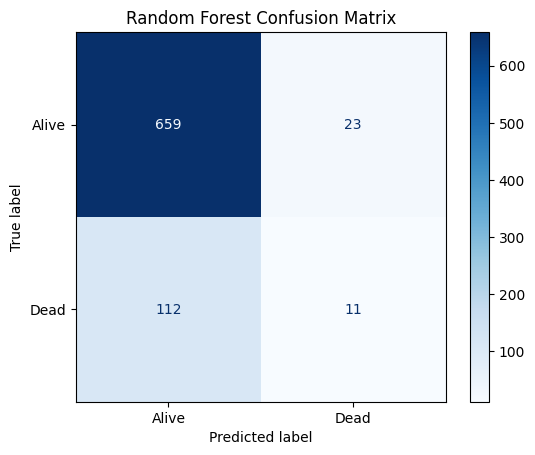


Top 10 Important Features:
                              Feature  Importance
0                            num__Age    0.182938
2         num__Regional Node Examined    0.168082
1                     num__Tumor Size    0.161437
3          num__Reginol Node Positive    0.103724
16                    cat__N Stage_N1    0.025674
8         cat__Marital Status_Married    0.024042
37  cat__Progesterone Status_Positive    0.021830
18                    cat__N Stage_N3    0.018105
36  cat__Progesterone Status_Negative    0.017646
10        cat__Marital Status_Single     0.017515


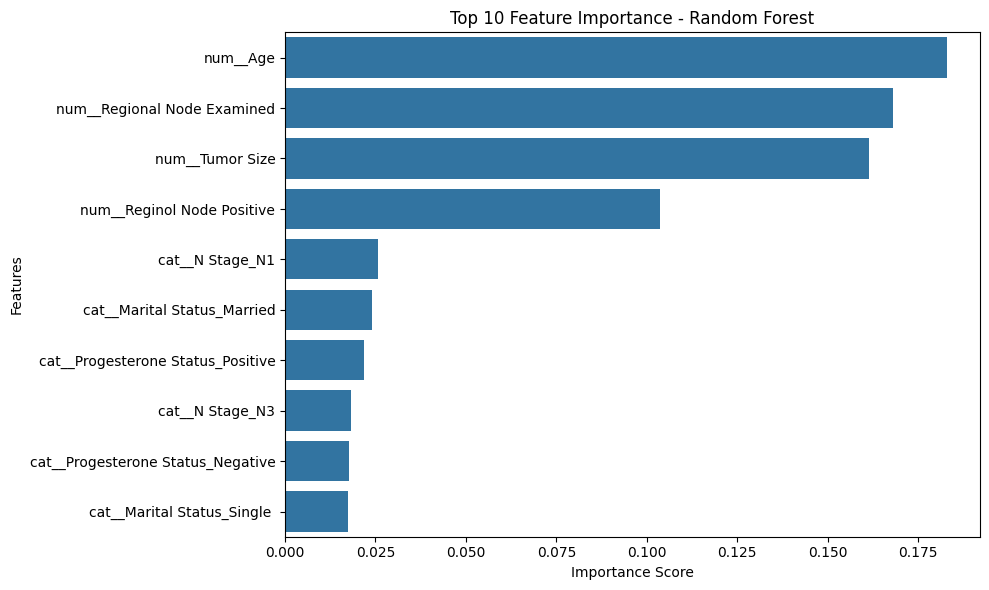


Actual vs Predicted Results:


,Actual Status,Predicted Status
0,Alive,Alive
1,Dead,Alive
2,Alive,Alive
3,Alive,Alive
4,Alive,Alive
5,Alive,Alive
6,Alive,Alive
7,Alive,Alive
8,Dead,Alive
9,Alive,Alive



Final Prediction: Alive
Actual Status: Alive

Random Forest Classification Completed Successfully!


In [ ]:

# RANDOM FOREST CLASSIFICATION - BREAST CANCER DATASET

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# 2. Load Dataset
df = pd.read_csv("Breast_Cancer.csv")

# Clean column names
df.columns = df.columns.str.strip()

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

# 3. Display Dataset Information
print("\nFirst 5 Records:")
display(df.head())

print("\nTarget Class Distribution:")
print(df["Status"].value_counts())

# 4. Separate Input Features and Target
# Survival Months is excluded to avoid data leakage
X = df.drop(columns=["Status", "Survival Months"])
y = df["Status"]

# 5. Identify Numerical and Categorical Columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# 6. Preprocess Data
numeric_transformer = SimpleImputer(strategy="median")

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

# 7. Split Dataset into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))

# 8. Create Random Forest Model
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# 9. Train the Model
rf_model.fit(X_train, y_train)

print("\nRandom Forest Model Trained Successfully!")

# 10. Make Predictions
y_pred = rf_model.predict(X_test)

# 11. Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# 12. Confusion Matrix
cm = confusion_matrix(
    y_test, y_pred,
    labels=rf_model.classes_
)

print("\nConfusion Matrix:")
print(cm)

# 13. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 14. Display Confusion Matrix Graph
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

disp.plot(cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()

# 15. Feature Importance
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

print("\nTop 10 Important Features:")
print(importance_df.head(10))

# 16. Feature Importance Graph
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# 17. Actual vs Predicted Results
results = pd.DataFrame({
    "Actual Status": y_test.values,
    "Predicted Status": y_pred
})

print("\nActual vs Predicted Results:")
display(results.head(15))

# 18. Final Prediction
sample = X_test.iloc[[0]]

prediction = rf_model.predict(sample)

print("\nFinal Prediction:", prediction[0])
print("Actual Status:", y_test.iloc[0])

print("\nRandom Forest Classification Completed Successfully!")


**Random forest using Regression**

Dataset Shape: (4024, 16)

First 5 Records:
   Age   Race Marital Status T Stage N Stage 6th Stage  \
0   68  White        Married      T1      N1       IIA   
1   50  White        Married      T2      N2      IIIA   
2   58  White       Divorced      T3      N3      IIIC   
3   58  White        Married      T1      N1       IIA   
4   47  White        Married      T2      N1       IIB   

               differentiate Grade   A Stage  Tumor Size Estrogen Status  \
0      Poorly differentiated     3  Regional           4        Positive   
1  Moderately differentiated     2  Regional          35        Positive   
2  Moderately differentiated     2  Regional          63        Positive   
3      Poorly differentiated     3  Regional          18        Positive   
4      Poorly differentiated     3  Regional          41        Positive   

  Progesterone Status  Regional Node Examined  Reginol Node Positive  \
0            Positive                      24                      1   
1     

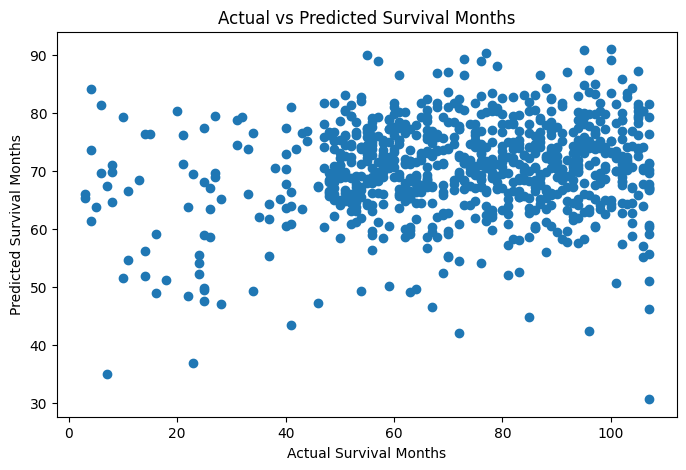


Sample Prediction:
Predicted Survival Months: 82.65
Actual Survival Months: 80


In [7]:

# Step 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Step 2: Load dataset

df = pd.read_csv("Breast_Cancer.csv")

df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())

# Step 3: Select features and target

X = df.drop(columns=["Survival Months", "Status"])
y = df["Survival Months"]

print("\nTarget: Survival Months")
print("Number of records:", len(y))

# Step 4: Identify numerical and categorical columns

numerical_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

# Step 5: Preprocessing

numerical_transformer = SimpleImputer(strategy="median")

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

# Step 6: Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# Step 7: Create Random Forest Regression model

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

# Step 8: Train model

model.fit(X_train, y_train)

print("\nRandom Forest Regression Model Trained Successfully!")

# Step 9: Make predictions

y_pred = model.predict(X_test)

# Step 10: Evaluate model

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nRegression Model Evaluation")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

# Step 11: Actual vs Predicted values

results = pd.DataFrame({
    "Actual Survival Months": y_test.values,
    "Predicted Survival Months": y_pred
})

print("\nActual vs Predicted Values:")
print(results.head(15))

# Step 12: Plot Actual vs Predicted values

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Survival Months")
plt.ylabel("Predicted Survival Months")
plt.title("Actual vs Predicted Survival Months")
plt.show()

# Step 13: Predict for one test record

sample_prediction = model.predict(X_test.iloc[[0]])

print("\nSample Prediction:")
print("Predicted Survival Months:", round(sample_prediction[0], 2))
print("Actual Survival Months:", y_test.iloc[0])
